<a href="https://colab.research.google.com/github/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution/blob/main/notebooks/01_data_setup_and_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data setup and EDA

Runs the manuscript's data steps on Colab: download the three datasets, check the folder labels,
build the 70/15/15 splits and run the EDA (section 3.5).

Before starting: **Runtime > Change runtime type > GPU** (needed later for training, not for this notebook),
and have your Kaggle API token (`kaggle.json`, from Kaggle > Settings > Create New Token) ready.

## 1. Get the code

In [ ]:
BRANCH = "main"
!git clone -b $BRANCH https://github.com/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution.git repo
%cd repo
!pip install -q -e ".[train,dev]" kaggle

Cloning into 'repo'...
remote: Enumerating objects: 81, done.
remote: Counting objects: 100% (81/81), done.
remote: Compressing objects: 100% (64/64), done.
remote: Total 81 (delta 14), reused 71 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (81/81), 37.64 KiB | 12.55 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for attribution (pyproject.toml) ... done


## 2. Optional: keep the datasets on Google Drive
Skip this on the free 15 GB Drive plan: the three datasets are well over 15 GB. Without it they go on
Colab's own disk (~70 GB free) and are re-downloaded each session, which takes a few minutes.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/thesis-data/raw
!rm -rf data/raw && ln -s /content/drive/MyDrive/thesis-data/raw data/raw

Mounted at /content/drive


## 3. Kaggle token
On Kaggle: Settings > API Tokens > **Legacy API Credentials**. That downloads `kaggle.json`.

In [ ]:
from google.colab import files
files.upload()  # choose kaggle.json
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


## 4. Download
Takes 20-40 minutes, mostly unzipping. Don't stop it partway: a stopped dataset is re-downloaded on the next run.

In [ ]:
!python scripts/download_datasets.py

kannan_ai_human_art: downloading kausthubkannan/ai-and-human-art-classification -> data/raw/kannan
Dataset URL: https://www.kaggle.com/datasets/kausthubkannan/ai-and-human-art-classification
License(s): DbCL-1.0
100% 2.21G/2.21G [02:11<00:00, 18.0MB/s]

superpotato9_ai_recognition: downloading superpotato9/dalle-recognition-dataset -> data/raw/superpotato9
Dataset URL: https://www.kaggle.com/datasets/superpotato9/dalle-recognition-dataset
License(s): MIT
100% 13.4G/13.4G [13:26<00:00, 17.9MB/s]

ai_artbench: downloading ravidussilva/real-ai-art -> data/raw/ai_artbench
Dataset URL: https://www.kaggle.com/datasets/ravidussilva/real-ai-art
License(s): other
100% 9.95G/9.95G [10:13<00:00, 17.4MB/s]



## 5. Check the folder labels
Every folder should show `human` or `ai`. If any show `UNMATCHED` or the wrong label,
fix the `classes` rules for that dataset in `configs/default.yaml` and re-run this cell.

In [ ]:
!python scripts/inspect_datasets.py


== kannan_ai_human_art (data/raw/kannan)
     43442  UNMATCHED  ai_art_classification/test
     10330  ai         ai_art_classification/train/AI_GENERATED
      8288  human      ai_art_classification/train/NON_AI_GENERATED

== superpotato9_ai_recognition (data/raw/superpotato9)
     17855  ai         fakeV2/fake-v2
      3780  human      real

== ai_artbench (data/raw/ai_artbench)
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_art_nouveau
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_baroque
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_expressionism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_impressionism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_post_impressionism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_realism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_renaissance
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_romanticism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_surrealism
 

## 6. Build the splits

In [16]:
!python scripts/prepare_data.py

kannan_ai_human_art: 18618 labeled images, 43442 unmatched
superpotato9_ai_recognition: 21635 labeled images, 0 unmatched
ai_artbench: 185015 labeled images, 0 unmatched
sampled label 0: {'superpotato9_ai_recognition': 3333, 'kannan_ai_human_art': 3333, 'ai_artbench': 3334}
sampled label 1: {'kannan_ai_human_art': 3333, 'superpotato9_ai_recognition': 3333, 'ai_artbench': 3334}
removed 55 duplicate images (0 with conflicting labels)
train: 13961 images
val: 2992 images
test: 2992 images


In [17]:
!python scripts/harmonize.py

train: 13961 images -> data/harmonized/train
val: 2992 images -> data/harmonized/val
test: 2992 images -> data/harmonized/test


## 7. EDA
Writes `outputs/eda/report.json` (class balance, image sizes, intensity/contrast, normalization
mean/std, leakage check) and `outputs/eda/per_image.csv`. Copy `train_normalization` into
`preprocess.mean` / `preprocess.std` in the config.

In [18]:
!python scripts/eda.py --max-per-split 2000

{
  "counts": {
    "train": 13961,
    "val": 2992,
    "test": 2992
  },
  "train_normalization": {
    "mean": [
      0.4827,
      0.4395,
      0.3883
    ],
    "std": [
      0.2823,
      0.2705,
      0.2714
    ]
  },
  "cross_split_duplicates": {}
}
full report: outputs/eda/report.json


In [19]:
import json, pandas as pd
report = json.load(open("outputs/eda/report.json"))
print(json.dumps(report["class_balance"], indent=1))
print("train normalization:", report["train_normalization"])
print("cross-split duplicates:", report["cross_split_duplicates"])
df = pd.read_csv("outputs/eda/per_image.csv")
df.groupby(["source", "label"])[["width", "height", "intensity", "contrast"]].describe().T

{
 "train": {
  "overall": {
   "0": {
    "n": 6995,
    "p": 0.5010386075496025
   },
   "1": {
    "n": 6966,
    "p": 0.49896139245039756
   }
  },
  "by_source": {
   "ai_artbench": {
    "0": {
     "n": 2308,
     "p": 0.49284646594063636
    },
    "1": {
     "n": 2375,
     "p": 0.5071535340593637
    }
   },
   "kannan_ai_human_art": {
    "0": {
     "n": 2325,
     "p": 0.5043383947939263
    },
    "1": {
     "n": 2285,
     "p": 0.4956616052060738
    }
   },
   "superpotato9_ai_recognition": {
    "0": {
     "n": 2362,
     "p": 0.5059982862039417
    },
    "1": {
     "n": 2306,
     "p": 0.4940017137960583
    }
   }
  }
 },
 "val": {
  "overall": {
   "0": {
    "n": 1499,
    "p": 0.5010026737967914
   },
   "1": {
    "n": 1493,
    "p": 0.4989973262032086
   }
  },
  "by_source": {
   "ai_artbench": {
    "0": {
     "n": 527,
     "p": 0.5285857572718154
    },
    "1": {
     "n": 470,
     "p": 0.47141424272818455
    }
   },
   "kannan_ai_human_art": {
    

source          ai_artbench             kannan_ai_human_art               \
label                     0           1                   0            1   
width     count  986.000000  976.000000          998.000000  1050.000000   
          mean   256.000000  256.000000          256.000000   256.000000   
          std      0.000000    0.000000            0.000000     0.000000   
          min    256.000000  256.000000          256.000000   256.000000   
          25%    256.000000  256.000000          256.000000   256.000000   
          50%    256.000000  256.000000          256.000000   256.000000   
          75%    256.000000  256.000000          256.000000   256.000000   
          max    256.000000  256.000000          256.000000   256.000000   
height    count  986.000000  976.000000          998.000000  1050.000000   
          mean   256.000000  256.000000          256.000000   256.000000   
          std      0.000000    0.000000            0.000000     0.000000   
          min    256.000000  256.000000          256.000000   256.000000   
          25%    256.000000  256.000000          256.000000   256.000000   
          50%    256.000000  256.000000          256.000000   256.000000   
          75%    256.000000  256.000000          256.000000   256.000000   
          max    256.000000  256.000000          256.000000   256.000000   
intensity count  986.000000  976.000000          998.000000  1050.000000   
          mean     0.469269    0.423941            0.466280     0.427697   
          std      0.165220    0.069137            0.174168     0.118381   
          min      0.113012    0.199706            0.034543     0.087126   
          25%      0.343138    0.377969            0.336996     0.357472   
          50%      0.460128    0.427453            0.460464     0.417303   
          75%      0.591101    0.469798            0.585579     0.488163   
          max      0.935880    0.662691            0.977032     0.949387   
contrast  count  986.000000  976.000000          998.000000  1050.000000   
          mean     0.187319    0.202383            0.199854     0.241021   
          std      0.056821    0.047821            0.060814     0.056538   
          min      0.023603    0.092181            0.014628     0.062695   
          25%      0.147650    0.167734            0.157716     0.200745   
          50%      0.185320    0.198070            0.199649     0.242836   
          75%      0.225309    0.227493            0.240357     0.277879   
          max      0.442281    0.407376            0.404523     0.433548   

source          superpotato9_ai_recognition              
label                                     0           1  
width     count                 1000.000000  990.000000  
          mean                   256.000000  256.000000  
          std                      0.000000    0.000000  
          min                    256.000000  256.000000  
          25%                    256.000000  256.000000  
          50%                    256.000000  256.000000  
          75%                    256.000000  256.000000  
          max                    256.000000  256.000000  
height    count                 1000.000000  990.000000  
          mean                   256.000000  256.000000  
          std                      0.000000    0.000000  
          min                    256.000000  256.000000  
          25%                    256.000000  256.000000  
          50%                    256.000000  256.000000  
          75%                    256.000000  256.000000  
          max                    256.000000  256.000000  
intensity count                 1000.000000  990.000000  
          mean                     0.485145    0.398979  
          std                      0.157980    0.157639  
          min                      0.021735    0.074969  
          25%                      0.387520    0.283471  
          50%                      0.479126    0.379218  
          75%          

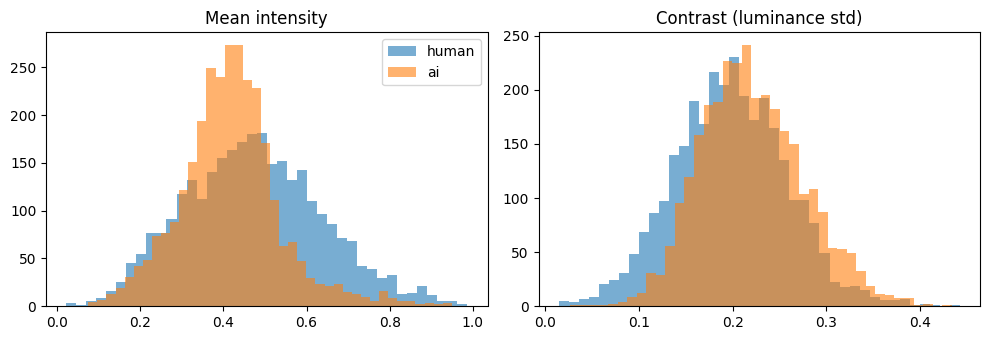

In [20]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for label, name in [(0, "human"), (1, "ai")]:
    d = df[df.label == label]
    axes[0].hist(d.intensity, bins=40, alpha=0.6, label=name)
    axes[1].hist(d.contrast, bins=40, alpha=0.6, label=name)
axes[0].set_title("Mean intensity"); axes[1].set_title("Contrast (luminance std)")
axes[0].legend(); plt.tight_layout()

## 8. Save the prepared data to Google Drive
Colab's disk is wiped when the session ends. This zips the harmonized images and split CSVs
(about 0.5 GB) into `MyDrive/thesis-data/` so the training notebooks can restore them in a minute
instead of re-downloading everything.

In [21]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/thesis-data
!zip -qr /content/drive/MyDrive/thesis-data/harmonized.zip data/harmonized data/processed
!ls -lh /content/drive/MyDrive/thesis-data/harmonized.zip

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
-rw------- 1 root root 562M Oct 21 14:52 /content/drive/MyDrive/thesis-data/harmonized.zip
